# Calculate an asymmetry score of a skin lesion 

In [4]:
import sys
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.resolve() # get project root directory

print(f"Project directory set to: {proj_dir}")

# Add the project root to the system path to import local modules
sys.path.append(str(proj_dir / 'python'))

Project directory set to: C:\Users\z004ps0b\Documents\dermascan


In [5]:
from dataset_manager import DatasetManager
from abcd_algorithms.asymmetry_scorer import calculate_asymmetry, calculate_asymmetry_skimage, get_largest_region_skimage
from abcd_algorithms.mask_utils import create_simple_binary_mask, boundary_extraction
from abcd_algorithms.border_scorer import calculate_rdv_metrics
from abcd_algorithms.asymmetry_scorer import rotate_mask_to_principal_axis
import matplotlib.pyplot as plt
import skimage.io as io
import pandas as pd

## Load the HAM10000 dataset

In [6]:
# load the dataset manager
dataset_manager = DatasetManager(
    data_dir=str(proj_dir / "data")
)

# load the dataset
# dataset = dataset_manager.load_dataset()
dataset_manager.load_cleaned_metadata()

## Get random image from dataset and calculate an asymmetry score using helper functions

Simple Asymmetry Score: 0.5867
Skimage Asymmetry Score: 0.6444
RDV Outline Score: 0.1875


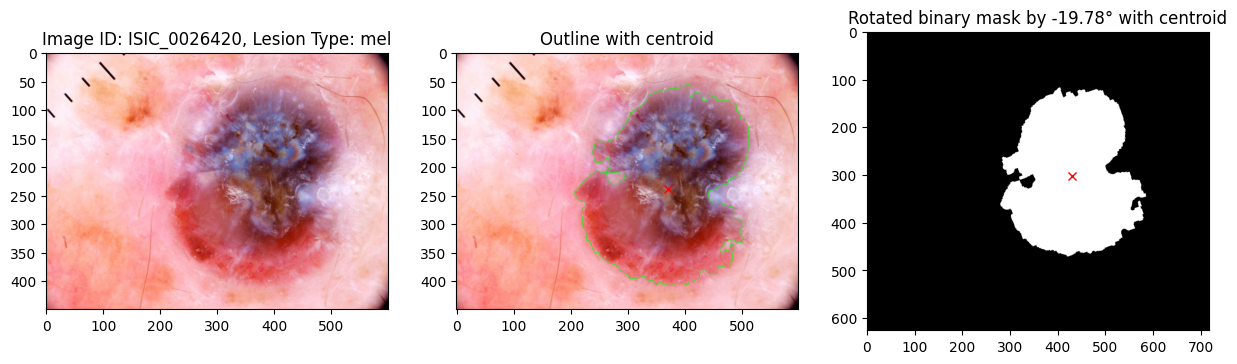

In [7]:
image_id, lesion_type, image = dataset_manager.get_sample_image(lesion_type=None)
binary_mask = create_simple_binary_mask(image=image)

# Calculate centroid and outline
y_centroid, x_centroid = get_largest_region_skimage(binary_mask).centroid
outline = boundary_extraction(binary_mask)
outline_score = calculate_rdv_metrics(binary_mask, centroid_x=x_centroid, centroid_y=y_centroid)

# Rotate mask to principal axis
rotated_binary_mask, angle = rotate_mask_to_principal_axis(binary_mask)
rotated_y_centroid, rotated_x_centroid = get_largest_region_skimage(rotated_binary_mask).centroid

# Calculate asymmetry scores
print(f"Simple Asymmetry Score: {calculate_asymmetry(image):.4f}")
print(f"Skimage Asymmetry Score: {calculate_asymmetry_skimage(image):.4f}")
print(f"RDV Outline Score: {outline_score:.4f}")

# Overlay original image with green boundary
outline_overlay = image.copy()
outline_overlay[outline > 0] = [0, 255, 0]

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image)
axes[0].set_title(f"Image ID: {image_id}, Lesion Type: {lesion_type}")
axes[1].imshow(outline_overlay)
axes[1].plot(x_centroid, y_centroid, 'rx')
axes[1].set_title("Outline with centroid")
axes[2].imshow(rotated_binary_mask, cmap='gray')
axes[2].plot(rotated_x_centroid, rotated_y_centroid, 'rx')
axes[2].set_title(f"Rotated binary mask by {angle:.2f}° with centroid")
plt.show()


Asymmetry Score Comparison by Lesion Type:
            simple_asymmetry                         skimage_asymmetry  \
                        mean     std     min     max              mean   
lesion_type                                                              
mel                   0.3954  0.2223  0.0002  0.8502            0.4706   
nv                    0.3471  0.2245  0.0002  0.8718            0.5408   

                                  
                std     min  max  
lesion_type                       
mel          0.2319  0.1031  1.0  
nv           0.2479  0.0772  1.0  


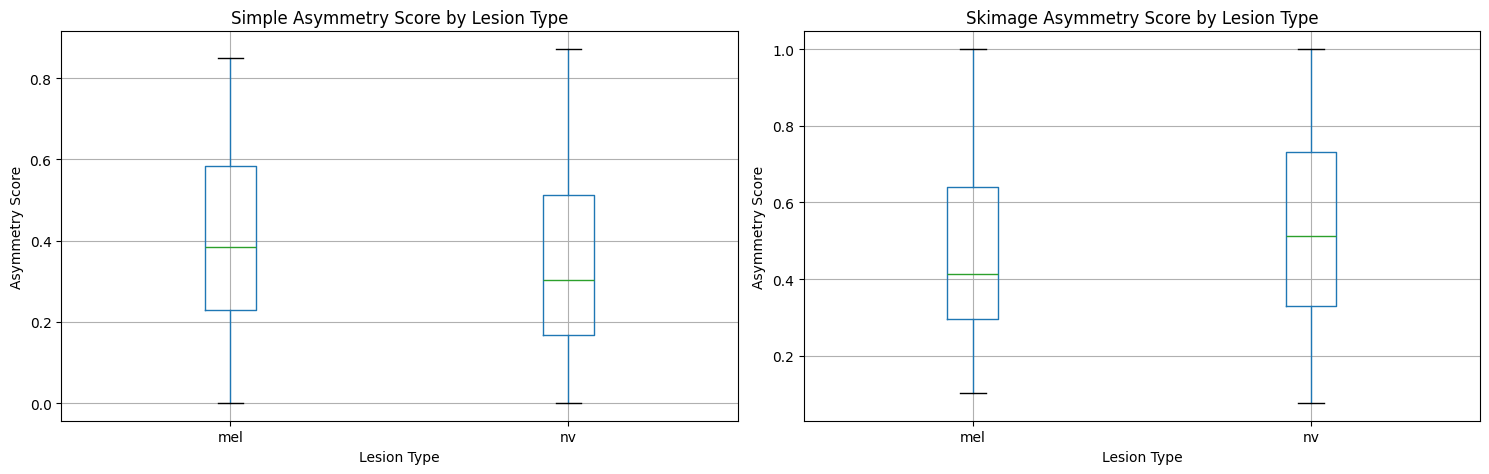


Correlation between Simple and Skimage methods:
                   simple_asymmetry  skimage_asymmetry
simple_asymmetry           1.000000          -0.384079
skimage_asymmetry         -0.384079           1.000000


In [8]:
# Compare asymmetry scores across lesion types for 1000 samples

# Initialize lists to store results
samples = dataset_manager.get_n_samples(n=1000)
results_list = []

for i in range(len(samples)):
    image_id = samples.iloc[i]['image_id']
    lesion_type = samples.iloc[i]['dx']
    image_path = samples.iloc[i]['image_path']
    img = io.imread(image_path)
    
    # Calculate asymmetry scores
    simple_score = calculate_asymmetry(img)
    skimage_score = calculate_asymmetry_skimage(img)
    
    # Store results
    results_list.append({
        'image_id': image_id,
        'lesion_type': lesion_type,
        'simple_asymmetry': simple_score,
        'skimage_asymmetry': skimage_score
    })

# Create DataFrame with results
results_df = pd.DataFrame(results_list)

# Calculate statistics by lesion type
comparison_stats = results_df.groupby('lesion_type').agg({
    'simple_asymmetry': ['mean', 'std', 'min', 'max'],
    'skimage_asymmetry': ['mean', 'std', 'min', 'max'],
}).round(4)

print("\nAsymmetry Score Comparison by Lesion Type:")
print(comparison_stats)

# Visualize the comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Box plot for simple asymmetry
results_df.boxplot(column='simple_asymmetry', by='lesion_type', ax=axes[0])
axes[0].set_title('Simple Asymmetry Score by Lesion Type')
axes[0].set_xlabel('Lesion Type')
axes[0].set_ylabel('Asymmetry Score')

# Box plot for skimage asymmetry
results_df.boxplot(column='skimage_asymmetry', by='lesion_type', ax=axes[1])
axes[1].set_title('Skimage Asymmetry Score by Lesion Type')
axes[1].set_xlabel('Lesion Type')
axes[1].set_ylabel('Asymmetry Score')

plt.suptitle('')
plt.tight_layout()
plt.show()

# Calculate correlation between the two methods
correlation = results_df[['simple_asymmetry', 'skimage_asymmetry']].corr()
print("\nCorrelation between Simple and Skimage methods:")
print(correlation)